# Student Performance Analytics System

**Technology:** Python, NumPy, Pandas

This notebook reads student data, calculates totals, averages, grades and pass/fail, and finds the top performers.

## Step 1: Import Libraries

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import functions as fn

## Step 2: Load the Dataset

In [2]:
df = fn.load_data('students.csv')
df.head()

,Student_ID,Name,Department,Maths,Physics,Chemistry,English,Computer,Attendance
0,1001,Aarav Yadav,CSE,56,77,64,53,52,70
1,1002,Deepak Singh,CE,51,82,58,71,82,99
2,1003,Riya Hooda,ME,53,69,69,75,71,81
3,1004,Deepak Hooda,CSE,82,78,62,74,73,75
4,1005,Divya Hooda,IT,60,68,72,66,63,75


## Step 3: Basic Information About the Data

In [3]:
print('Number of records:', len(df))
print('Number of columns:', len(df.columns))
print('Missing values:', int(df.isnull().sum().sum()))
df.info()

Number of records: 60
Number of columns: 9
Missing values: 0
<class 'pandas.DataFrame'>
RangeIndex: 60 entries, 0 to 59
Data columns (total 9 columns):
 #   Column      Non-Null Count  Dtype
---  ------      --------------  -----
 0   Student_ID  60 non-null     int64
 1   Name        60 non-null     str  
 2   Department  60 non-null     str  
 3   Maths       60 non-null     int64
 4   Physics     60 non-null     int64
 5   Chemistry   60 non-null     int64
 6   English     60 non-null     int64
 7   Computer    60 non-null     int64
 8   Attendance  60 non-null     int64
dtypes: int64(7), str(2)
memory usage: 4.3 KB


In [4]:
df.describe()

,Student_ID,Maths,Physics,Chemistry,English,Computer,Attendance
count,60.000000,60.000000,60.000000,60.000000,60.000000,60.000000,60.000000
mean,1030.500000,61.050000,62.616667,61.650000,63.316667,63.883333,79.066667
std,17.464249,15.970762,15.993740,15.400666,14.936580,14.924774,11.816201
min,1001.000000,28.000000,23.000000,27.000000,25.000000,32.000000,50.000000
25%,1015.750000,51.000000,53.000000,54.000000,53.000000,51.500000,72.000000
50%,1030.500000,60.500000,61.500000,64.500000,61.500000,67.000000,79.500000
75%,1045.250000,72.750000,75.000000,71.250000,74.250000,73.250000,87.000000
max,1060.000000,94.000000,99.000000,92.000000,95.000000,99.000000,99.000000


## Step 4: Total and Average Marks (NumPy)

In [5]:
df = fn.calculate_total_and_average(df)
df[['Student_ID', 'Name', 'Total', 'Average']].head(10)

,Student_ID,Name,Total,Average
0,1001,Aarav Yadav,302,60.4
1,1002,Deepak Singh,344,68.8
2,1003,Riya Hooda,337,67.4
3,1004,Deepak Hooda,369,73.8
4,1005,Divya Hooda,329,65.8
5,1006,Divya Yadav,301,60.2
6,1007,Arjun Malik,258,51.6
7,1008,Ankit Sharma,384,76.8
8,1009,Sahil Hooda,221,44.2
9,1010,Aditya Malik,250,50.0


## Step 5: Grades and Pass / Fail

**Grading rule:** 90+ A+, 80+ A, 70+ B, 60+ C, 50+ D, 40+ E, below 40 F.

**Pass rule:** a student must score at least 40 in every subject.

In [6]:
df = fn.assign_grades(df)
df = fn.assign_results(df)
df = fn.attendance_status(df)
df[['Name', 'Total', 'Average', 'Grade', 'Result', 'Attendance_Status']].head(10)

,Name,Total,Average,Grade,Result,Attendance_Status
0,Aarav Yadav,302,60.4,C,Pass,Shortage
1,Deepak Singh,344,68.8,C,Pass,OK
2,Riya Hooda,337,67.4,C,Pass,OK
3,Deepak Hooda,369,73.8,B,Pass,OK
4,Divya Hooda,329,65.8,C,Pass,OK
5,Divya Yadav,301,60.2,C,Pass,OK
6,Arjun Malik,258,51.6,D,Pass,Shortage
7,Ankit Sharma,384,76.8,B,Pass,Shortage
8,Sahil Hooda,221,44.2,E,Fail,OK
9,Aditya Malik,250,50.0,D,Fail,OK


## Step 6: Class Summary

In [7]:
summary = fn.class_summary(df)
for key, value in summary.items():
    print(key, ':', value)

total_students : 60
class_average : 62.5
highest_average : 92.4
lowest_average : 34.0
best_student : Aarav Sharma
weakest_student : Vivaan Malik
passed : 48
failed : 12
pass_percentage : 80.0
attendance_shortage : 19


## Step 7: Subject-wise Performance

In [8]:
subjects = fn.subject_analysis(df)
subjects

,Subject,Average,Highest,Lowest,Passed,Failed
0,Maths,61.05,94,28,54,6
1,Physics,62.62,99,23,55,5
2,Chemistry,61.65,92,27,54,6
3,English,63.32,95,25,57,3
4,Computer,63.88,99,32,57,3


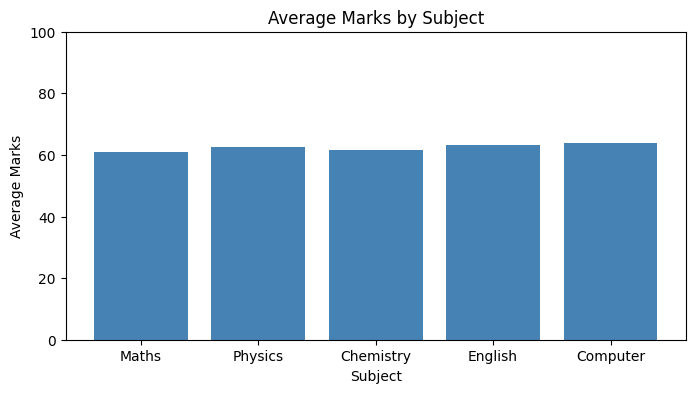

In [9]:
plt.figure(figsize=(8, 4))
plt.bar(subjects['Subject'], subjects['Average'], color='steelblue')
plt.title('Average Marks by Subject')
plt.xlabel('Subject')
plt.ylabel('Average Marks')
plt.ylim(0, 100)
plt.show()

## Step 8: Department-wise Performance

In [10]:
departments = fn.department_analysis(df)
departments

,Department,Students,Average_Marks,Average_Attendance,Passed
0,CE,7,54.11,85.86,4
1,CSE,17,66.31,78.29,16
2,ECE,12,66.88,75.50,11
3,IT,10,60.10,76.80,6
4,ME,14,60.04,81.29,11


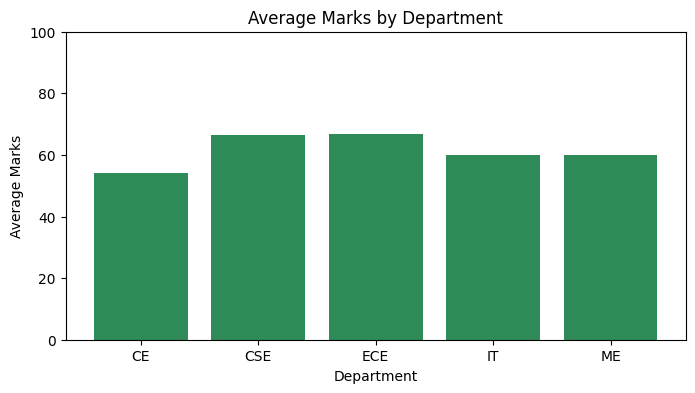

In [11]:
plt.figure(figsize=(8, 4))
plt.bar(departments['Department'], departments['Average_Marks'], color='seagreen')
plt.title('Average Marks by Department')
plt.xlabel('Department')
plt.ylabel('Average Marks')
plt.ylim(0, 100)
plt.show()

## Step 9: Grade Distribution

In [12]:
grades = fn.grade_distribution(df)
grades

,Grade,Students
0,A+,1
1,A,4
2,B,14
3,C,18
4,D,13
5,E,7
6,F,3


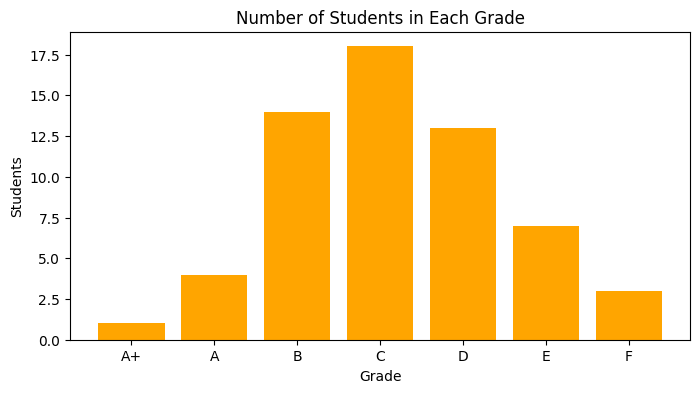

In [13]:
plt.figure(figsize=(8, 4))
plt.bar(grades['Grade'], grades['Students'], color='orange')
plt.title('Number of Students in Each Grade')
plt.xlabel('Grade')
plt.ylabel('Students')
plt.show()

## Step 10: Pass vs Fail

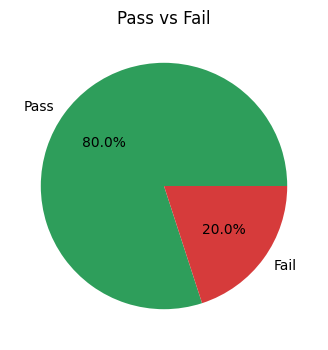

In [14]:
counts = df['Result'].value_counts()
plt.figure(figsize=(4, 4))
plt.pie(counts, labels=counts.index, autopct='%1.1f%%', colors=['#2e9e5b', '#d63b3b'])
plt.title('Pass vs Fail')
plt.show()

## Step 11: Top 5 Students

In [15]:
top = fn.top_performers(df, 5)
top

,Student_ID,Name,Department,Total,Average,Grade
14,1015,Aarav Sharma,CSE,462,92.4,A+
23,1024,Neha Hooda,IT,440,88.0,A
15,1016,Mohit Hooda,ME,430,86.0,A
55,1056,Ankit Gupta,CSE,406,81.2,A
48,1049,Anjali Malik,ME,402,80.4,A


## Step 12: Failed Students

In [16]:
failed = df[df['Result'] == 'Fail']
failed[['Student_ID', 'Name', 'Department', 'Average']]

,Student_ID,Name,Department,Average
8,1009,Sahil Hooda,CSE,44.2
9,1010,Aditya Malik,IT,50.0
11,1012,Nikhil Singh,CE,48.0
16,1017,Pankaj Gupta,ECE,50.6
21,1022,Riya Yadav,IT,39.0
22,1023,Nikhil Dahiya,ME,41.0
30,1031,Yash Hooda,IT,51.8
36,1037,Yash Malik,ME,35.0
38,1039,Karan Sharma,CE,40.8
41,1042,Vivaan Malik,CE,34.0


## Step 13: Attendance and Marks

Correlation between attendance and average marks: -0.07


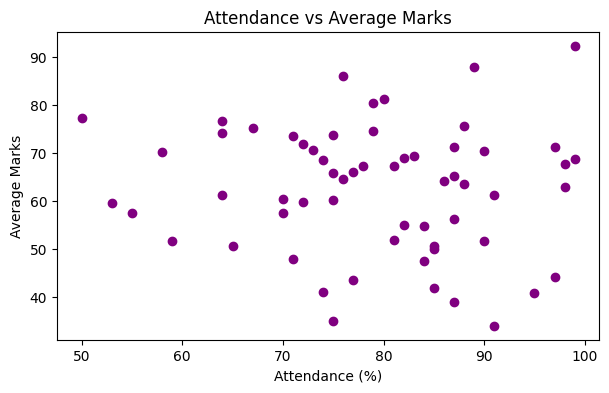

In [17]:
correlation = np.corrcoef(df['Attendance'], df['Average'])[0, 1]
print('Correlation between attendance and average marks:', round(correlation, 2))

plt.figure(figsize=(7, 4))
plt.scatter(df['Attendance'], df['Average'], color='purple')
plt.title('Attendance vs Average Marks')
plt.xlabel('Attendance (%)')
plt.ylabel('Average Marks')
plt.show()

## Conclusion

- The class has 60 students and the pass percentage is shown in the summary above.
- The best and weakest subjects were found using subject-wise averages.
- Top performers were found by sorting students by average marks.